## EDA

In [1]:
#Charger le dataset de radiographies thoraciques fourni pour le projet.

import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia


In [2]:
# Explorer la structure des dossiers et identifier les classes présentes.
from pathlib import Path

data_dir = Path(path) / "chest_xray"

train_dir = data_dir / "train"
test_dir = data_dir / "test"
val_dir = data_dir / "val"

print("Train :", train_dir)
print("Test :", test_dir)
print("Validation :", val_dir)

Train : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train
Test : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test
Validation : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/val


In [3]:
# Vérifier le nombre d'images disponibles dans chaque classe.
# Vérifier la répartition des images entre les classes NORMAL et PNEUMONIA.
normal = 0
peneumonia =0
for nom, dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    print(f"\n{nom} :")

    for element in dossier.iterdir():
        if element.is_dir():
            images =list(element.iterdir())
            print(f"{element.name} :{len(images)} images")
            if element.name == "PNEUMONIA":
                peneumonia +=len(images)
            else :
                normal +=len(images)
print("normal" ,normal)
print("peneumonia",peneumonia)



Train :
PNEUMONIA :3875 images
NORMAL :1341 images

Test :
PNEUMONIA :390 images
NORMAL :234 images

Validation :
PNEUMONIA :8 images
NORMAL :8 images
normal 1583
peneumonia 4273


In [4]:
# Identifier les éventuels problèmes liés aux images et gérer les erreurs de chargement.
from PIL import Image

for nom, dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    erreurs = []

    for classe in dossier.iterdir():
        if classe.is_dir():
            for images in classe.iterdir():
                try:
                    with Image.open(images) as img:
                        img.verify()
                except Exception:
                    erreurs.append(images)

    print(f"{nom} : {len(erreurs)} images problématiques")

Train : 0 images problématiques
Test : 0 images problématiques
Validation : 0 images problématiques


In [5]:
for nom ,dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    for fichier in dossier.iterdir():
        if fichier.is_dir():
            images =list(fichier.iterdir())
            print(fichier.name)
            for image in images:
                with Image.open(image) as img:
                    print(img.size)
                    print(img.mode)
                    print(img.format)


PNEUMONIA
(1024, 712)
L
JPEG
(1424, 1016)
L
JPEG
(1376, 1208)
L
JPEG
(1336, 1256)
L
JPEG
(895, 516)
RGB
JPEG
(1120, 656)
L
JPEG
(1084, 717)
RGB
JPEG
(2000, 1896)
L
JPEG
(856, 568)
L
JPEG
(840, 488)
L
JPEG
(1144, 832)
L
JPEG
(1072, 648)
L
JPEG
(1120, 768)
L
JPEG
(1408, 1152)
L
JPEG
(1381, 1044)
L
JPEG
(1240, 920)
L
JPEG
(1120, 680)
L
JPEG
(1184, 880)
L
JPEG
(1024, 632)
L
JPEG
(976, 656)
L
JPEG
(1240, 928)
L
JPEG
(1472, 1048)
L
JPEG
(1456, 896)
L
JPEG
(1248, 832)
L
JPEG
(1010, 562)
RGB
JPEG
(1336, 808)
L
JPEG
(1428, 884)
L
JPEG
(1518, 1149)
L
JPEG
(1248, 808)
L
JPEG
(896, 504)
L
JPEG
(824, 568)
L
JPEG
(1392, 832)
L
JPEG
(1256, 680)
L
JPEG
(1080, 680)
L
JPEG
(1094, 829)
L
JPEG
(703, 457)
RGB
JPEG
(1328, 1368)
L
JPEG
(1944, 1555)
L
JPEG
(1144, 808)
L
JPEG
(856, 568)
L
JPEG
(1128, 752)
L
JPEG
(1176, 776)
L
JPEG
(1528, 1152)
L
JPEG
(1080, 776)
L
JPEG
(1184, 624)
L
JPEG
(1120, 736)
L
JPEG
(984, 672)
L
JPEG
(904, 544)
L
JPEG
(1080, 744)
L
JPEG
(1424, 1112)
L
JPEG
(1300, 890)
L
JPEG
(1416, 800)

In [6]:
# Redimensionner les images à une taille fixe de 180 × 180 pixels et les convertir au format RGB.

for nom ,dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    for fichier in dossier.iterdir():
        if fichier.is_dir():
            for image in fichier.iterdir():
                with Image.open(image) as img:
                    img =img.resize((180,180))
                    img =img.convert("RGB")
                    print(img.size , img.mode)


(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180) RGB
(180, 180)

In [7]:
import tensorflow as tf
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(180,180),
    batch_size= 32,
    color_mode="rgb"
)

test_ds =tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(180,180),
    batch_size=32,
    color_mode="rgb"
)

val_ds =tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(180,180),
    batch_size=32,
    color_mode="rgb"
)
print("Classes :", train_ds.class_names)

Found 5216 files belonging to 2 classes.


2026-10-18 15:34:59.751020: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 624 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


In [8]:
for images, labels in train_ds.take(1):
    print("Images :", images.shape)
    print("Labels :", labels.shape)

Images : (32, 180, 180, 3)
Labels : (32,)


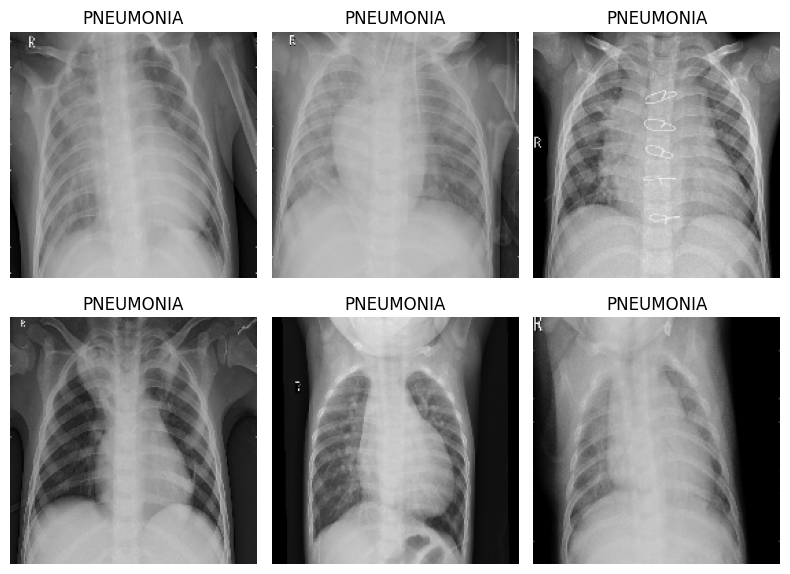

In [9]:
#Visualisation des radiographies.
import matplotlib.pyplot as plt

class_names = train_ds.class_names

for images, labels in train_ds.take(1):
    plt.figure(figsize=(8, 6))

    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [10]:
# #Normalisation des pixels, par exemple de [0, 255] vers [0, 1]
# from tensorflow.keras.layers import Rescaling

# normalisation =Rescaling(1./255)
# train_ds =train_ds.map(
#     lambda images,labels:(normalisation(images),labels)
# )

# test_ds =test_ds.map(
#     lambda images ,labels:(normalisation(images),labels)
# )

# val_ds =val_ds.map(
#     lambda images,labels:(normalisation(images),labels)
# )



In [11]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    # Entrée : images 180 × 180 avec 3 canaux
    Input(shape=(180, 180, 3)),

    # Normalisation : valeurs de 0-255 vers 0-1
    Rescaling(1./255),

    # Bloc convolutionnel 1
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Classification
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.metrics import BinaryAccuracy ,Precision,Recall,AUC
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc"),
        ]
)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)



In [14]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Récupérer tous les labels du dataset d'entraînement
y_train = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

# Identifier les classes présentes
classes = np.unique(y_train)

# Calculer les poids équilibrés
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Associer chaque classe à son poids
class_weights = dict(zip(classes.astype(int), weights))

# print("Classes :", train_ds.class_names)
# print("Poids des classes :", class_weights)


In [15]:
import numpy as np
import time



start= time.time()

history = model.fit(
    train_ds,
    epochs=10,
    class_weight = class_weights,
    batch_size=32,
    validation_data=val_ds,
    callbacks = [early_stopping]
)

end = time.time()

training_duration = end - start

print(f"Durée d'entraînement : {training_duration:.2f} secondes")
print(f"Durée en minutes : {training_duration / 60:.2f} minutes")



Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.8675 - auc: 0.9465 - loss: 0.3038 - precision: 0.9528 - recall: 0.8645 - val_accuracy: 0.7500 - val_auc: 0.9375 - val_loss: 0.4456 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.9538 - auc: 0.9880 - loss: 0.1322 - precision: 0.9856 - recall: 0.9517 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1940 - val_precision: 1.0000 - val_recall: 0.7500
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 198s 1s/step - accuracy: 0.9638 - auc: 0.9932 - loss: 0.0984 - precision: 0.9891 - recall: 0.9618 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1051 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.9758 - auc: 0.9966 - loss: 0.0654 - precision: 0.9932 - recall: 0.9742 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0528 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 7/10
163/163 ━━━━━━━━━

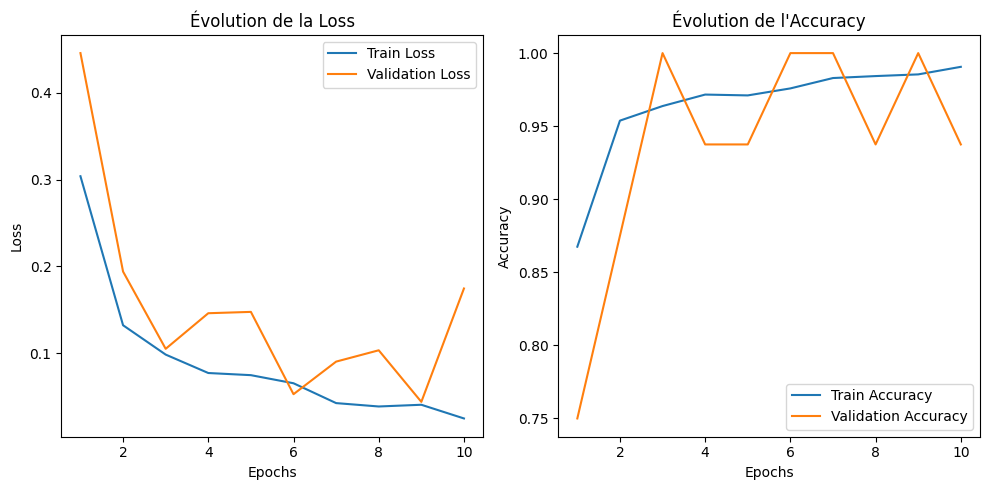

In [16]:
#visualiser les courbes d'apprentissage
train_loss =history.history["loss"]
val_loss =history.history["val_loss"]

train_accuracy =history.history["accuracy"]
val_accuracy =history.history["val_accuracy"]

epochs =range(1,len(train_loss) + 1)

plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label="Train Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
results = model.evaluate(test_ds, return_dict=True)

for metric, value in results.items():
    print(f"{metric} : {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 365ms/step - accuracy: 0.7676 - auc: 0.8817 - loss: 0.9862 - precision: 0.7324 - recall: 0.9897
accuracy : 0.7676
auc : 0.8817
loss : 0.9862
precision : 0.7324
recall : 0.9897


In [21]:
import numpy as np

y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
])

y_prob = model.predict(test_ds)

y_pred = (y_prob.ravel() >= 0.5).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 379ms/step


In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.34      0.14      0.20       234
   PNEUMONIA       0.62      0.84      0.71       390

    accuracy                           0.58       624
   macro avg       0.48      0.49      0.46       624
weighted avg       0.51      0.58      0.52       624



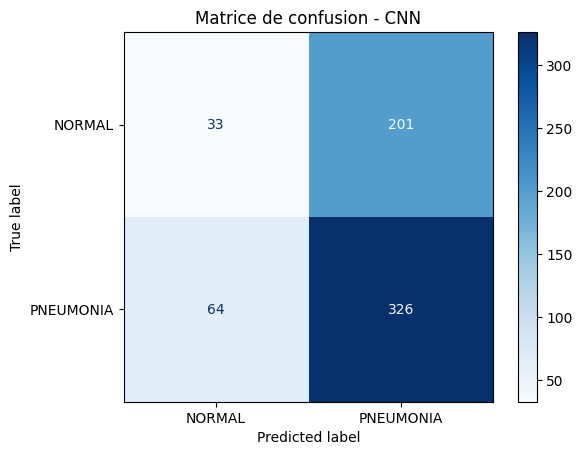

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["NORMAL", "PNEUMONIA"],
    cmap="Blues"
)

plt.title("Matrice de confusion - CNN")
plt.show()

In [24]:
model.save("chest_xray_cnn.keras")

In [25]:
from tensorflow import keras

model = keras.models.load_model("chest_xray_cnn.keras")